## 1. 설정 불러오기와 성별 방향 계산

In [3]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append("..")
from src.utils import *
from src.prompts import *

tok, enc = load_text_encoder()
d_layers, diffs = gender_direction(DIRECTION_PAIRS, TEMPLATES, tok, enc, space="layers")
print(d_layers.shape, diffs.shape)   # (13, 768) (7, 13, 768) 이 나오면 성공

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

(13, 768) (7, 13, 768)


## 2. 검증 1: 따로 둔 쌍의 투영값 (남 − 여 > 0 인가)

In [6]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 검증 1: 따로 둔 쌍에서 층마다 남성 투영값 > 여성 투영값인가
held = encode_words([m for m,_ in HELDOUT_PAIRS] + [f for _,f in HELDOUT_PAIRS],
                    TEMPLATES, tok, enc)["layers"]          # (6, 13, 768)
proj = np.einsum("nld,ld->nl", held, d_layers)              # (6, 13)
k = len(HELDOUT_PAIRS)
gap = proj[:k] - proj[k:]                                   # 쌍별 (남 − 여), 양수면 통과
print(np.round(gap, 2))

[[ 0.000e+00  0.000e+00 -1.000e-02  1.700e-01  2.200e-01  2.400e-01
   5.900e-01  1.490e+00  1.610e+00  1.940e+00  2.960e+00  6.040e+00
   8.480e+00]
 [ 0.000e+00  4.000e-02  3.000e-02  3.600e-01  4.200e-01  4.500e-01
   1.030e+00  1.620e+00  1.770e+00  2.560e+00  3.910e+00  7.450e+00
   9.300e+00]
 [ 0.000e+00  4.300e-01  4.800e-01  5.500e-01  5.500e-01  4.000e-01
   6.700e-01  1.260e+00  1.030e+00  1.290e+00  1.770e+00  7.480e+00
   1.029e+01]]


## 3. 검증 2: 층별 차이 벡터 PCA (성별을 축 하나로 봐도 되나)

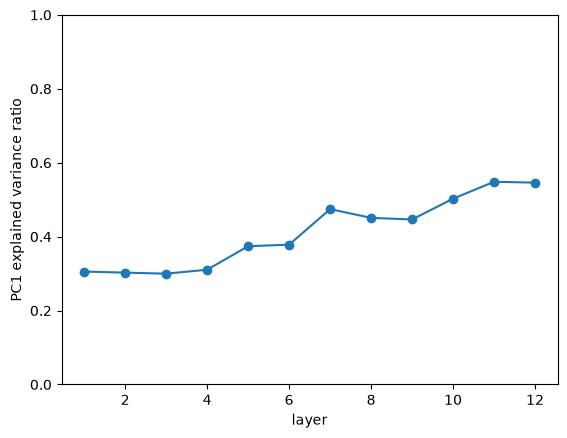

In [9]:
def pc1_ratio(X):
    s = np.linalg.svd(X, compute_uv=False)   # 평균을 빼지 않음
    return s[0]**2 / (s**2).sum()

ratios = [pc1_ratio(diffs[:, l]) for l in range(1, 13)]
plt.plot(range(1, 13), ratios, marker="o")
plt.xlabel("layer"); plt.ylabel("PC1 explained variance ratio"); plt.ylim(0, 1)
plt.show()

np.save("../data/gender_dir_layers.npy", d_layers)

In [10]:
# 층별 비교용: 그 층 벡터들의 전형적인 크기로 나눔
scale = np.linalg.norm(held, axis=-1).mean(axis=0)   # (13,)
print(np.round(gap / scale, 3))

[[ 0.     0.001 -0.003  0.042  0.043  0.044  0.093  0.195  0.183  0.18
   0.197  0.328  0.435]
 [ 0.     0.013  0.008  0.089  0.085  0.084  0.163  0.212  0.202  0.238
   0.26   0.404  0.477]
 [ 0.     0.137  0.14   0.134  0.11   0.074  0.106  0.165  0.117  0.12
   0.118  0.406  0.527]]


## 5. 개입용 성별 방향 (최종 출력 공간)

In [11]:
d_final, diffs_final = gender_direction(DIRECTION_PAIRS, TEMPLATES, tok, enc, space="final")
print("PC1 비율 (final):", round(pc1_ratio(diffs_final), 3))

# 13번째 층 방향과 얼마나 비슷한지 (layer norm 때문에 같지 않음)
print("cos(d_final, d_layer12):", round(float(d_final @ d_layers[12]), 3))

np.save("../data/gender_dir_final.npy", d_final)

PC1 비율 (final): 0.568
cos(d_final, d_layer12): 0.99
